# What is linked with unhappy Olist customers?

**Summary (every number comes from the outputs below):**
- **Late delivery has the strongest link found:** 9.31% of on-time orders got a 1-2 star review, against 79.36% of orders 8+ days late. Many late orders were rated before the parcel arrived.
- **Most late deliveries had the seller hand over on time (77.65%)**; for them, the carrier part took a median of 28 days, against 7 for on-time deliveries.
- **Even on on-time orders, some categories stand out:** office furniture had 17.15% unhappy orders, against 8.48% for all on-time single-product orders.

These are patterns in past orders (things that go together), not proof that one thing causes another.

**Contents:** 1. Setup · 2. One row per order · 3. Baseline · 4. Monthly trend · 5. Delivery promise ·
6. Seller hand-over vs carrier · 7. Categories (on-time orders) · 8. Sellers · 9. Order value and repeat orders ·
10. Worth testing · 11. Limitations

**Full project** (PostgreSQL pipeline, 13 data quality tests, every query):
[github.com/RishitheB0T/olist-customer-experience-analytics](https://github.com/RishitheB0T/olist-customer-experience-analytics)

## 1. Setup
Kaggle can't reach the project's PostgreSQL database, so this notebook uses **DuckDB**: a small SQL
database that runs inside Python and reads the CSV files directly. The SQL is close to the
PostgreSQL version on GitHub. "Unhappy" = a 1-2 star review, and every rate says what it is out of.

In [1]:
import glob
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

try:
    import duckdb
except ModuleNotFoundError:   # not installed on this machine: install it (needs internet)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "duckdb"])
    import duckdb

# Find the Olist files: on Kaggle under /kaggle/input, locally in the project's data/raw folder
found = (glob.glob("/kaggle/input/**/olist_orders_dataset.csv", recursive=True)
         or glob.glob("../../data/raw/olist_orders_dataset.csv"))
DATA = Path(found[0]).parent
print("data folder:", DATA, "| duckdb", duckdb.__version__)

data folder: ..\..\data\raw | duckdb 2.0.0


In [2]:
con = duckdb.connect()   # an in-memory database: it exists only while this notebook runs

def query(sql: str) -> pd.DataFrame:
    """Run one SQL query and return the result as a table."""
    return con.execute(sql).df()

FILES = {
    "orders": "olist_orders_dataset.csv",          "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv", "reviews": "olist_order_reviews_dataset.csv",
    "customers": "olist_customers_dataset.csv",     "sellers": "olist_sellers_dataset.csv",
    "products": "olist_products_dataset.csv",       "categories": "product_category_name_translation.csv",
}
for table, file in FILES.items():   # one table per CSV; DuckDB guesses each column's type
    con.execute(f"CREATE TABLE {table} AS SELECT * FROM read_csv('{(DATA / file).as_posix()}', header = true)")

# Row counts, to compare with the files on the dataset page
query(" UNION ALL ".join(f"SELECT '{t}' AS table_name, count(*) AS row_count FROM {t}" for t in FILES))

,table_name,row_count
0,orders,99441
1,items,112650
2,payments,103886
3,reviews,99224
4,customers,99441
5,sellers,3095
6,products,32951
7,categories,71


In [3]:
# One chart style: light surface, grey axes and grid, one blue for single-series charts
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, BLUE = "#e1e0d9", "#c3c2b7", "#2a78d6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "figure.dpi": 110,
})

## 2. One row per order
Every question below starts from one table with one row per order, built with the same rules as the
GitHub pipeline:
- **Review:** some orders have several reviews; the **lowest** score counts (ties: the latest answer),
  because the project studies unhappy customers.
- **Days:** whole calendar days, ignoring the time of day. `days_late` above 0 = late.
- **Seller and product:** kept only when the order has exactly one, so a review can be tied to them.
- **Stage dates:** `stages_usable` is false when an order's dates can't be split into a seller part and
  a carrier part (several hand-over deadlines, a deadline 60+ days after purchase, or impossible dates).

In [4]:
con.execute("""
CREATE OR REPLACE TABLE order_facts AS
WITH item_summary AS (            -- items per order
  SELECT order_id,
         count(DISTINCT seller_id) AS n_sellers,
         CASE WHEN count(DISTINCT seller_id) = 1 THEN min(seller_id) END AS seller_id,     -- only if one seller
         CASE WHEN count(DISTINCT product_id) = 1 THEN min(product_id) END AS product_id,  -- only if one product
         CASE WHEN count(DISTINCT shipping_limit_date) = 1 THEN min(shipping_limit_date) END AS deadline
  FROM items GROUP BY order_id
), paid AS (                      -- total paid per order
  SELECT order_id, sum(payment_value) AS paid_total FROM payments GROUP BY order_id
), chosen_review AS (             -- one review per order: lowest score, then latest answer, then review_id
  SELECT order_id, review_score, review_answer_timestamp
  FROM reviews
  QUALIFY row_number() OVER (PARTITION BY order_id
                             ORDER BY review_score, review_answer_timestamp DESC, review_id) = 1
)
SELECT o.order_id, o.order_status, c.customer_unique_id,
       o.order_purchase_timestamp AS purchased, o.order_delivered_customer_date AS delivered,
       date_diff('day', o.order_estimated_delivery_date::date, o.order_delivered_customer_date::date) AS days_late,
       date_diff('day', o.order_delivered_carrier_date::date, o.order_delivered_customer_date::date) AS carrier_days,
       o.order_delivered_carrier_date::date > i.deadline::date AS handover_late,   -- NULL unless one deadline
       i.deadline IS NOT NULL
         AND date_diff('day', o.order_purchase_timestamp::date, i.deadline::date) <= 60
         AND o.order_delivered_carrier_date >= o.order_purchase_timestamp
         AND o.order_delivered_customer_date >= o.order_delivered_carrier_date AS stages_usable,
       coalesce(i.n_sellers, 0) AS n_sellers, i.seller_id, i.product_id, p.paid_total,
       r.review_score IS NOT NULL AS has_review, r.review_score,
       r.review_score <= 2 AS is_unhappy,                                         -- NULL when no review
       r.review_answer_timestamp AS rated
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
LEFT JOIN item_summary i  ON i.order_id = o.order_id
LEFT JOIN paid p          ON p.order_id = o.order_id
LEFT JOIN chosen_review r ON r.order_id = o.order_id
""")
query("SELECT count(*) AS orders, count(*) FILTER (WHERE has_review) AS reviewed_orders FROM order_facts")

,orders,reviewed_orders
0,99441,98673


## 3. Baseline
The main KPI is the **unhappy order rate**: orders with a 1-2 star review ÷ orders with a review.

In [5]:
query("""
SELECT CASE WHEN order_status = 'delivered' THEN 'delivered' ELSE 'not delivered' END AS status_group,
       count(*) AS orders,
       count(*) FILTER (WHERE has_review) AS reviewed,
       round(100.0 * count(*) FILTER (WHERE is_unhappy) / count(*) FILTER (WHERE has_review), 2) AS unhappy_pct,
       round(avg(review_score), 2) AS avg_score,
       round(100.0 * count(*) FILTER (WHERE is_unhappy)
             / sum(count(*) FILTER (WHERE is_unhappy)) OVER (), 2) AS share_of_all_unhappy_pct
FROM order_facts
GROUP BY status_group
UNION ALL
SELECT 'all orders', count(*), count(*) FILTER (WHERE has_review),
       round(100.0 * count(*) FILTER (WHERE is_unhappy) / count(*) FILTER (WHERE has_review), 2),
       round(avg(review_score), 2), 100
FROM order_facts
ORDER BY orders DESC
""")

,status_group,orders,reviewed,unhappy_pct,avg_score,share_of_all_unhappy_pct
0,all orders,99441,98673,14.73,4.08,100.00
1,delivered,96478,95832,12.85,4.15,84.71
2,not delivered,2963,2841,78.21,1.74,15.29


About 1 in 7 reviewed orders is unhappy. Orders that never arrived (canceled, unavailable, ...) are few
but mostly unhappy; sections 5-6 study delivered orders only, so they leave these out.

## 4. Monthly trend
Orders by purchase month, Jan 2017 - Aug 2018 (the months outside this range are almost empty).
On-time rate is out of delivered orders with both dates; unhappy rate is out of reviewed orders.
Two panels share the month axis instead of one chart with two y-scales.

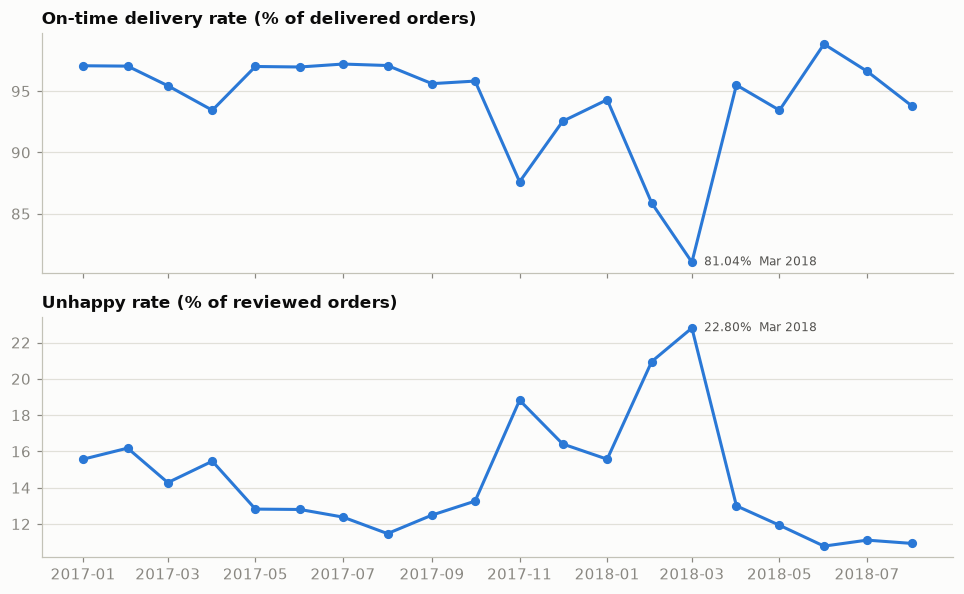

In [6]:
monthly = query("""
SELECT date_trunc('month', purchased) AS month,
       count(*) AS orders,
       round(100.0 * count(*) FILTER (WHERE order_status = 'delivered' AND days_late <= 0)
             / count(*) FILTER (WHERE order_status = 'delivered' AND days_late IS NOT NULL), 2) AS on_time_pct,
       round(100.0 * count(*) FILTER (WHERE is_unhappy) / count(*) FILTER (WHERE has_review), 2) AS unhappy_pct
FROM order_facts
WHERE purchased >= DATE '2017-01-01' AND purchased < DATE '2018-09-01'
GROUP BY month
ORDER BY month
""")
monthly["month"] = pd.to_datetime(monthly["month"])

fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
panels = [("on_time_pct", "On-time delivery rate (% of delivered orders)", "min"),
          ("unhappy_pct", "Unhappy rate (% of reviewed orders)", "max")]
for ax, (col, title, pick) in zip(axes, panels):
    ax.plot(monthly["month"], monthly[col], color=BLUE, marker="o", markersize=5)
    i = monthly[col].idxmin() if pick == "min" else monthly[col].idxmax()   # label only the extreme month
    ax.annotate(f"{monthly.loc[i, col]:.2f}%  {monthly.loc[i, 'month']:%b %Y}",
                (monthly.loc[i, "month"], monthly.loc[i, col]),
                textcoords="offset points", xytext=(8, 0), va="center", color=INK_2, fontsize=8)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

Months with fewer on-time deliveries had more unhappy customers: the lowest on-time month is also the
highest unhappy month.

## 5. Delivery promise: does lateness go with unhappiness?
Delivered orders with a delivery date and a promised date. `orders` counts all of them; the unhappy
rates use the reviewed ones. Some customers rated **before** their parcel arrived (the survey can be
sent at the promised date), so the table also splits each band by when the customer rated.

In [7]:
p1 = query("""
SELECT CASE WHEN days_late <= 0 THEN '1. on time or early'
            WHEN days_late <= 3 THEN '2. 1-3 days late'
            WHEN days_late <= 7 THEN '3. 4-7 days late'
            ELSE '4. 8+ days late' END AS days_late_band,
       count(*) AS orders,
       count(*) FILTER (WHERE has_review) AS reviewed,
       round(100.0 * count(*) FILTER (WHERE is_unhappy) / count(*) FILTER (WHERE has_review), 2) AS unhappy_pct,
       count(*) FILTER (WHERE rated >= delivered) AS rated_after_arrival,
       round(100.0 * count(*) FILTER (WHERE is_unhappy AND rated >= delivered)
             / count(*) FILTER (WHERE rated >= delivered), 2) AS unhappy_pct_after,
       count(*) FILTER (WHERE rated < delivered) AS rated_before_arrival,
       round(100.0 * count(*) FILTER (WHERE is_unhappy AND rated < delivered)
             / count(*) FILTER (WHERE rated < delivered), 2) AS unhappy_pct_before
FROM order_facts
WHERE order_status = 'delivered' AND days_late IS NOT NULL
GROUP BY days_late_band
ORDER BY days_late_band
""")
p1

,days_late_band,orders,reviewed,unhappy_pct,rated_after_arrival,unhappy_pct_after,rated_before_arrival,unhappy_pct_before
0,1. on time or early,89936,89443,9.31,89242,9.28,201,21.39
1,2. 1-3 days late,1870,1852,32.18,1435,18.61,417,78.90
2,3. 4-7 days late,1802,1748,67.68,396,20.45,1352,81.51
3,4. 8+ days late,2862,2781,79.36,76,30.26,2705,80.74


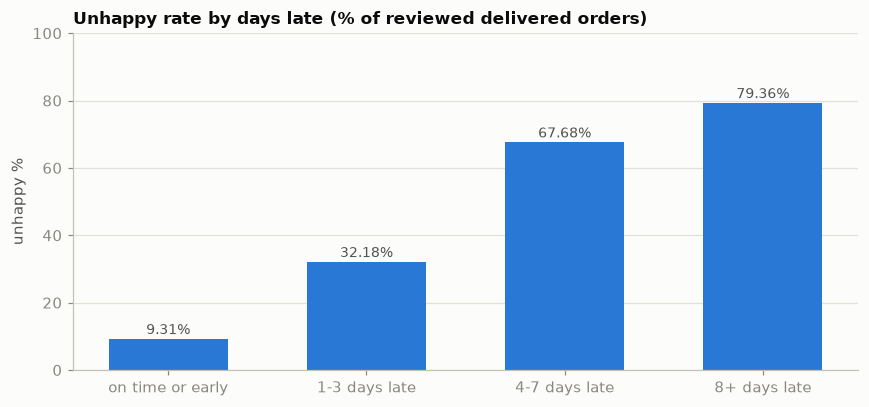

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8))
labels = p1["days_late_band"].str[3:]   # drop the "1. " sort prefix
ax.bar(labels, p1["unhappy_pct"], color=BLUE, width=0.6)
for x, v in zip(labels, p1["unhappy_pct"]):
    ax.annotate(f"{v:.2f}%", (x, v), textcoords="offset points", xytext=(0, 3),
                ha="center", color=INK_2, fontsize=9)
ax.set_ylim(0, 100)
ax.set_title("Unhappy rate by days late (% of reviewed delivered orders)")
ax.set_ylabel("unhappy %")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

The unhappy rate climbs with every lateness band. Within each late band, customers who rated before
arrival were far more often unhappy than those who rated after. Among those who rated after arrival
the rate still rises with lateness, though the 8+ days group is small.

## 6. Seller hand-over vs carrier
A delivery has two parts: the seller hands the parcel to the carrier (against a deadline), then the
carrier takes it to the customer. Orders with usable stage dates only (section 2). `pct_of_delivery_group`
answers "of late deliveries, how many had a late seller?".

In [9]:
query("""
SELECT CASE WHEN days_late > 0 THEN 'delivery late' ELSE 'delivery on time' END AS delivery,
       CASE WHEN handover_late THEN 'seller late' ELSE 'seller on time' END AS hand_over,
       count(*) AS orders,
       round(100.0 * count(*) / sum(count(*)) OVER (
             PARTITION BY CASE WHEN days_late > 0 THEN 'delivery late' ELSE 'delivery on time' END), 2)
           AS pct_of_delivery_group,
       median(carrier_days) AS median_carrier_days,
       count(*) FILTER (WHERE has_review) AS reviewed,
       round(100.0 * count(*) FILTER (WHERE is_unhappy) / count(*) FILTER (WHERE has_review), 2) AS unhappy_pct
FROM order_facts
WHERE order_status = 'delivered' AND days_late IS NOT NULL AND stages_usable
GROUP BY delivery, hand_over
ORDER BY delivery, hand_over
""")

,delivery,hand_over,orders,pct_of_delivery_group,median_carrier_days,reviewed,unhappy_pct
0,delivery late,seller late,1460,22.35,14.0,1423,63.88
1,delivery late,seller on time,5071,77.65,28.0,4955,62.08
2,delivery on time,seller late,4096,4.58,7.0,4063,14.57
3,delivery on time,seller on time,85320,95.42,7.0,84865,8.91


Most late deliveries had the seller hand over on time, and their carrier part was much longer than
usual. A late hand-over that still arrived on time goes with a higher unhappy rate than when both
were on time.

## 7. Categories, on-time orders only
Reviewed orders whose items are all one product (so the review belongs to one category), delivered
on time, so lateness is kept out. Only categories with 500+ such orders are ranked. The dashed line
is all on-time single-product orders.

In [10]:
categories = query("""
WITH names AS (   -- English names, plus 2 categories missing from the translation file
  SELECT product_category_name, product_category_name_english AS category FROM categories
  UNION ALL
  SELECT * FROM (VALUES ('portateis_cozinha_e_preparadores_de_alimentos', 'portable_kitchen_and_food_preparers'),
                        ('pc_gamer', 'pc_gamer'))
)
SELECT coalesce(n.category, 'unknown') AS category,
       count(*) AS reviewed_on_time,
       count(*) FILTER (WHERE f.is_unhappy) AS unhappy_on_time,
       round(100.0 * count(*) FILTER (WHERE f.is_unhappy) / count(*), 2) AS unhappy_on_time_pct
FROM order_facts f
JOIN products p    ON p.product_id = f.product_id
LEFT JOIN names n  ON n.product_category_name = p.product_category_name
WHERE f.has_review AND f.order_status = 'delivered' AND f.days_late <= 0
GROUP BY coalesce(n.category, 'unknown')
""")
ranked = categories[categories["reviewed_on_time"] >= 500].sort_values("unhappy_on_time_pct")
reference = 100 * categories["unhappy_on_time"].sum() / categories["reviewed_on_time"].sum()
print(f"{len(ranked)} categories ranked; all on-time single-product orders: {reference:.2f}% unhappy")
ranked.sort_values("unhappy_on_time_pct", ascending=False).head(5)

26 categories ranked; all on-time single-product orders: 8.48% unhappy


,category,reviewed_on_time,unhappy_on_time,unhappy_on_time_pct
10,office_furniture,1102,189,17.15
49,unknown,1223,146,11.94
17,computers_accessories,5879,619,10.53
23,telephony,3683,376,10.21
69,bed_bath_table,7766,791,10.19


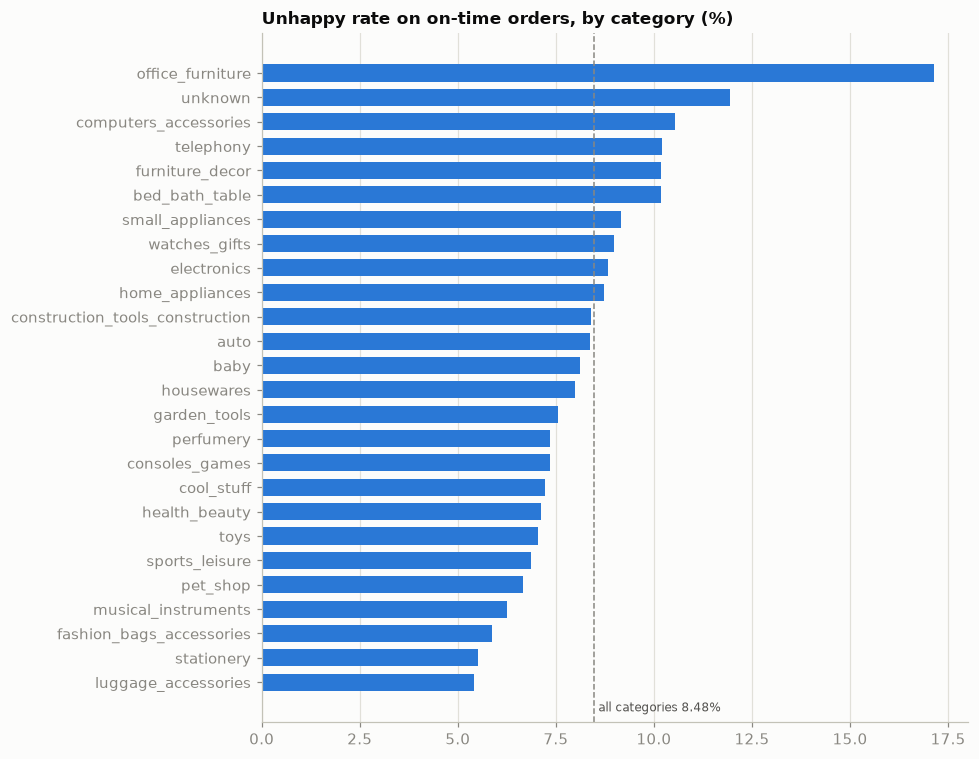

In [11]:
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(ranked["category"], ranked["unhappy_on_time_pct"], color=BLUE, height=0.7)
ax.axvline(reference, color=MUTED, linestyle="--", linewidth=1)
ax.text(reference, -1.2, f" all categories {reference:.2f}%", color=INK_2, fontsize=8)
ax.set_title("Unhappy rate on on-time orders, by category (%)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

Office furniture stands well above the line even when delivery was on time, and so do products with no
category ("unknown"). Luggage and stationery are lowest.

## 8. Sellers
Reviewed single-seller orders (multi-seller orders can't be given to one seller). **By count:** sellers
are ranked by how many unhappy reviews they have. **By rate:** sellers with 50+ on-time reviewed orders,
compared with the usual on-time rate.

In [12]:
query("""
WITH per_seller AS (
  SELECT seller_id, count(*) AS reviewed, count(*) FILTER (WHERE is_unhappy) AS unhappy
  FROM order_facts WHERE n_sellers = 1 AND has_review
  GROUP BY seller_id
), ranked AS (
  SELECT *, row_number() OVER (ORDER BY unhappy DESC, reviewed DESC, seller_id) AS seller_rank,
         count(*) OVER () AS all_sellers, sum(unhappy) OVER () AS all_unhappy, sum(reviewed) OVER () AS all_reviewed
  FROM per_seller
)
SELECT 'top ' || t.top_pct || '%' AS sellers_group,
       count(*) AS sellers,
       round(100.0 * sum(unhappy) / max(all_unhappy), 2)   AS share_of_unhappy_pct,
       round(100.0 * sum(reviewed) / max(all_reviewed), 2) AS share_of_reviewed_orders_pct
FROM ranked
JOIN (VALUES (1), (5), (10), (20)) AS t(top_pct) ON seller_rank <= ceil(all_sellers * t.top_pct / 100.0)
GROUP BY t.top_pct
ORDER BY t.top_pct
""")

,sellers_group,sellers,share_of_unhappy_pct,share_of_reviewed_orders_pct
0,top 1%,31,28.44,25.14
1,top 5%,154,56.75,51.39
2,top 10%,308,71.41,65.92
3,top 20%,615,84.80,80.04


In [13]:
query("""
WITH on_time AS (
  SELECT seller_id, count(*) AS reviewed_on_time, count(*) FILTER (WHERE is_unhappy) AS unhappy_on_time
  FROM order_facts
  WHERE n_sellers = 1 AND has_review AND order_status = 'delivered' AND days_late <= 0
  GROUP BY seller_id
), usual AS (SELECT 1.0 * sum(unhappy_on_time) / sum(reviewed_on_time) AS rate FROM on_time)
SELECT round(100 * u.rate, 2) AS usual_on_time_unhappy_pct,
       count(*) FILTER (WHERE reviewed_on_time >= 50) AS sellers_50_plus,
       count(*) FILTER (WHERE reviewed_on_time >= 50 AND 1.0 * unhappy_on_time / reviewed_on_time >= 2 * u.rate)
           AS at_least_twice_usual,
       round(max(100.0 * unhappy_on_time / reviewed_on_time) FILTER (WHERE reviewed_on_time >= 50), 2) AS worst_pct
FROM on_time, usual u
GROUP BY u.rate
""")

,usual_on_time_unhappy_pct,sellers_50_plus,at_least_twice_usual,worst_pct
0,8.77,393,25,54.02


By count, the top sellers hold only a little more of the unhappy reviews than of the orders, so the count
mostly reflects size. By rate, a short list of sellers has at least twice the usual unhappy rate even on
on-time orders.

## 9. Order value and repeat orders
**Value:** total paid in unhappy orders, as a share of all reviewed order value (value *associated with*
unhappy orders, not money lost). **Repeat orders:** per person, the clock starts when they answered the
review of their first order; did they order again within 180 days? Only people whose full 180 days fit
before the data ends (treated as 2018-08-31) count.

In [14]:
query("""
SELECT round(sum(paid_total), 2) AS reviewed_value,
       round(sum(paid_total) FILTER (WHERE is_unhappy), 2) AS unhappy_value,
       round(100.0 * sum(paid_total) FILTER (WHERE is_unhappy) / sum(paid_total), 2) AS unhappy_share_of_value_pct,
       round(100.0 * count(*) FILTER (WHERE is_unhappy) / count(*), 2) AS unhappy_share_of_orders_pct
FROM order_facts
WHERE has_review AND paid_total IS NOT NULL
""")

,reviewed_value,unhappy_value,unhappy_share_of_value_pct,unhappy_share_of_orders_pct
0,15859105.79,2769252.32,17.46,14.73


In [15]:
query("""
WITH person_orders AS (
  SELECT customer_unique_id AS person, purchased, has_review, is_unhappy, rated,
         row_number() OVER (PARTITION BY customer_unique_id ORDER BY purchased, order_id) AS nth_order
  FROM order_facts
), anchors AS (       -- each person's first order, if reviewed: the clock starts when they answered
  SELECT person, is_unhappy, rated AS anchor FROM person_orders WHERE nth_order = 1 AND has_review
), next_order AS (    -- their first order placed after that moment
  SELECT a.person, min(o.purchased) AS next_purchase
  FROM anchors a JOIN person_orders o ON o.person = a.person AND o.purchased > a.anchor
  GROUP BY a.person
)
SELECT CASE WHEN a.is_unhappy THEN 'unhappy' ELSE 'other' END AS first_review,
       count(*) AS people_full_window,
       count(*) FILTER (WHERE n.next_purchase <= a.anchor + INTERVAL 180 DAY) AS ordered_again,
       round(100.0 * count(*) FILTER (WHERE n.next_purchase <= a.anchor + INTERVAL 180 DAY) / count(*), 2)
           AS ordered_again_pct
FROM anchors a
LEFT JOIN next_order n ON n.person = a.person
WHERE a.anchor + INTERVAL 180 DAY < TIMESTAMP '2018-09-01'
GROUP BY first_review
ORDER BY first_review DESC
""")

,first_review,people_full_window,ordered_again,ordered_again_pct
0,unhappy,7729,103,1.33
1,other,45793,826,1.80


Unhappy orders carry a larger share of value than of orders. Very few people order again at all, so
the repeat comparison rests on small numbers; whether the gap is bigger than chance is checked in the
next phase of the project.

## 10. Worth testing
Early ideas from these patterns. None is proven to work; each needs a test.
1. **Carrier part of late deliveries.** Most late deliveries had the seller on time. *Test:* on a few
   routes that are often late, try a change with the carrier (or a delay message to the customer) for a
   random half of orders, and compare unhappy rates with the other half.
2. **When the survey is sent.** Many late orders were rated before arrival. *Test:* send the survey after
   confirmed delivery for a random half of orders and compare scores; this would also make the score a
   cleaner measure.
3. **Sellers with high unhappy rates on on-time orders.** *Test:* offer a listing and packing check to
   some of these sellers, and compare them with similar sellers who didn't get it.

## 11. Limitations
1. **Patterns, not causes.** Late orders, far routes and some categories differ in many ways at once.
2. **Some ratings came before the parcel**, which raises unhappy rates for late orders.
3. **Reviewed orders only** for every rate with scores: they describe customers who answered.
4. **Narrower bases:** categories use single-product orders, sellers use single-seller orders. For
   multi-seller orders, one recorded delivery date may not cover every parcel.
5. **Provisional minimums** (500 orders per category, 50 per seller) and no chance checks yet; the
   GitHub project adds them in its statistics phase.
6. **Old, single-company data:** one Brazilian marketplace, 2016-2018.